## ReLU MLP Single-Seed Learning Dynamics

This notebook runs a standard fully connected ReLU network with a single training phase.

It focuses on one seed to inspect learning dynamics clearly (checkpoints, scatter alignment, and start/end metrics).

No dropout, normalization, or multi-phase logic is used.

In [34]:
from pathlib import Path

from itables import show
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

%load_ext autoreload
%autoreload 2

from layer_lenses.odt import samples_reaching_node
from layer_lenses.odt import odt_leaf_ids_for_x
from layer_lenses.relu_analysis import (
    collect_start_end_metrics,
    first_layer_odt_alignment,
    masked_accuracy_by_odt_leaf,
    neuron_leaf_responsibility_from_ablation,
    plot_first_layer_odt_alignment,
    plot_layered_relu_graph,
    quadratic_snapshot_epochs,
    run_single_relu_seed,
    summarize_neuron_responsibility,
)
from layer_lenses.relu_analysis import log_loss_gradients
from layer_lenses.relu_training import checkpoint_model_from_state
from layer_lenses.relu_analysis import activation_tensor_by_layer_neuron_data

from pathlib import Path
import pickle
from typing import Any

def save_seed_result_pickle(seed_result: dict[str, Any], path: str | Path) -> Path:
    """Save seed_result to a pickle file."""
    out_path = Path(path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with out_path.open("wb") as f:
        pickle.dump(seed_result, f, protocol=pickle.HIGHEST_PROTOCOL)
    return out_path


def load_seed_result_pickle(path: str | Path) -> dict[str, Any]:
    """Load seed_result from a pickle file."""
    in_path = Path(path)
    with in_path.open("rb") as f:
        obj = pickle.load(f)
    if not isinstance(obj, dict):
        raise TypeError(f"Expected dict from pickle, got {type(obj).__name__}")
    return obj


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [85]:


# Scratch-aligned defaults with a plain ReLU MLP.
DIM = 100
DEPTH = 5
N_TRAIN = 1_000_000
HIDDEN_DIMS = [100]

TOTAL_EPOCHS = 2000
LR = 2e-3
BATCH_SIZE = 1000
WEIGHT_DECAY = 0.01

SNAPSHOT_EPOCHS = range(0,TOTAL_EPOCHS,1)
print(f"Using {len(SNAPSHOT_EPOCHS)} snapshot epochs.")

SEED = 5178

seed_result = None

Using 2000 snapshot epochs.


## Run selected seed

This is the expensive cell. It runs single-phase ReLU MLP training for the selected seed.

In [86]:
print(f"Running seed {SEED} ...")
seed_result = run_single_relu_seed(
    SEED,
    dim=DIM,
    depth=DEPTH,
    n_train=N_TRAIN,
    hidden_dims=HIDDEN_DIMS,
    total_epochs=TOTAL_EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    weight_decay=WEIGHT_DECAY,
    snapshot_epochs=SNAPSHOT_EPOCHS,
    project_first_layer_grad_orthogonal=None,
    odt_hyperplanes = "coordinate_axes",
    bias= False,
    device="cpu"
)
print("Done")

Running seed 5178 ...


Training ReLU MLP:   0%|          | 0/2001 [00:00<?, ?it/s]

Done


In [ ]:

# Save
# save_path = save_seed_result_pickle(seed_result, "results/cache/seed_result_5178_5_40_40_40_1Mtrain_1000batch.pkl")
# print("Saved to:", save_path)

# Load
# seed_result = load_seed_result_pickle("results/cache/seed_result_5178.pkl")
# print(seed_result.keys())

dict_keys(['master_seed', 'seeds', 'tree', 'meta', 'data', 'out'])


In [71]:
seed_result["data"]["x_train"].shape

(1000000, 100)

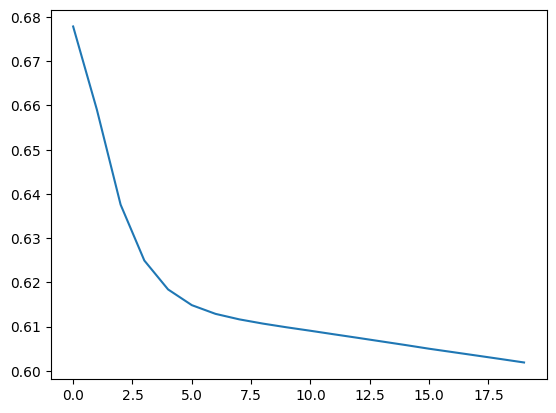

In [82]:
plt.plot(seed_result["out"]["epoch_losses"][:20])
out = seed_result["out"]
ckpts = out["checkpoint_snapshots"]
tree = seed_result["tree"]

## Scatter plot and gating dynamics analysis

In [87]:
for name, param in ckpts[499].items():
    print(name, param.shape)

hidden_layers.0.weight torch.Size([100, 100])
output_layer.weight torch.Size([1, 100])


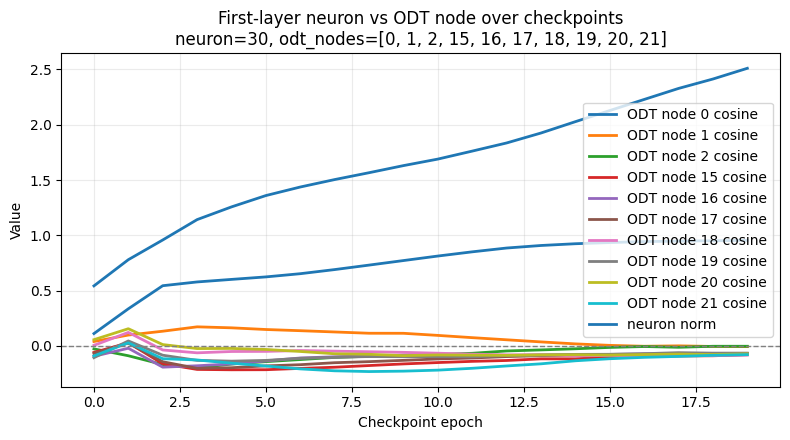

In [95]:
FIRST_LAYER_NEURON_ID = [30]
ODT_INTERNAL_NODE_ID = [0,1,2]+list[int](range(15,22))
NUM_POINTS_PLOT = 20



neuron_ids = list(FIRST_LAYER_NEURON_ID)
odt_node_ids = list(ODT_INTERNAL_NODE_ID)

if not neuron_ids:
    raise ValueError("FIRST_LAYER_NEURON_ID must not be empty.")
if not odt_node_ids:
    raise ValueError("ODT_INTERNAL_NODE_ID must not be empty.")

first_layer_width = ckpts[0]["hidden_layers.0.weight"].shape[0]
internal_node_count = tree.w_list.shape[0]

for neuron_id in neuron_ids:
    if not (0 <= neuron_id < first_layer_width):
        raise ValueError(
            f"Each FIRST_LAYER_NEURON_ID must be in [0, {first_layer_width - 1}], "
            f"got {neuron_id}."
        )

for odt_node_id in odt_node_ids:
    if not (0 <= odt_node_id < internal_node_count):
        raise ValueError(
            f"Each ODT_INTERNAL_NODE_ID must be in [0, {internal_node_count - 1}], "
            f"got {odt_node_id}."
        )

epochs = sorted(ckpts.keys())[:NUM_POINTS_PLOT]

odt_vectors = {
    odt_node_id: torch.from_numpy(tree.w_list[odt_node_id]).float()
    for odt_node_id in odt_node_ids
}
odt_norms = {
    odt_node_id: float(torch.norm(vector).clamp_min(1e-12))
    for odt_node_id, vector in odt_vectors.items()
}

fig, axes = plt.subplots(
    nrows=len(neuron_ids),
    ncols=1,
    figsize=(8, 4.5 * len(neuron_ids)),
    sharex=True,
    squeeze=False,
)
axes = axes[:, 0]

for ax, neuron_id in zip(axes, neuron_ids):
    neuron_norms = []
    normalized_inner_products = {
        odt_node_id: [] for odt_node_id in odt_node_ids
    }

    for epoch in epochs:
        w = (
            ckpts[epoch]["hidden_layers.0.weight"][neuron_id]
            .detach()
            .cpu()
            .float()
        )
        w_norm = float(torch.norm(w).clamp_min(1e-12))
        neuron_norms.append(w_norm)

        for odt_node_id in odt_node_ids:
            cosine = float(
                torch.dot(w, odt_vectors[odt_node_id])
                / (w_norm * odt_norms[odt_node_id])
            )
            normalized_inner_products[odt_node_id].append(cosine)

    for odt_node_id in odt_node_ids:
        label = (
            "normalized inner product (cosine)"
            if len(odt_node_ids) == 1
            else f"ODT node {odt_node_id} cosine"
        )
        ax.plot(
            epochs,
            normalized_inner_products[odt_node_id],
            linewidth=2.0,
            label=label,
        )

    ax.plot(
        epochs,
        neuron_norms,
        linewidth=2.0,
        label="neuron norm",
    )
    ax.axhline(0.0, color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel("Value")
    ax.set_title(
        "First-layer neuron vs ODT node over checkpoints\n"
        f"neuron={neuron_id}, odt_nodes={odt_node_ids}"
    )
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Checkpoint epoch")
fig.tight_layout()
plt.show()

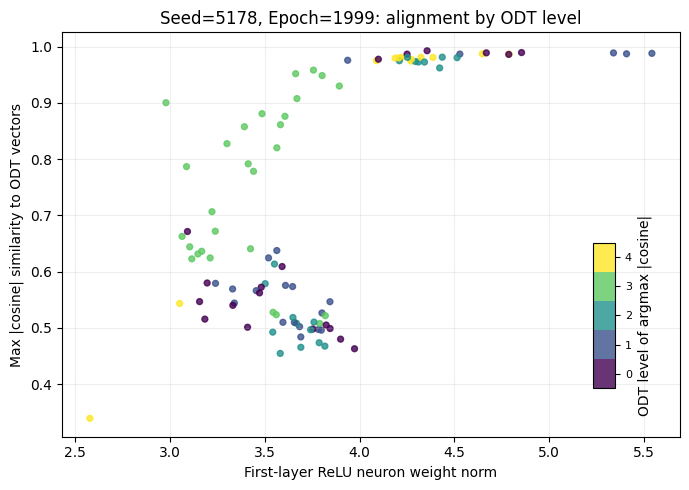

In [97]:
EPOCH = list(ckpts.keys())[1999]  # choose from available checkpoints

alignment, fig, ax = plot_first_layer_odt_alignment(
    state_dict=ckpts[EPOCH],
    tree=tree,
    depth=DEPTH,
    epoch=EPOCH,
    seed=SEED,
)
plt.show()

# Keep these names available for downstream scratch cells.
first_layer_wts = alignment["first_layer_wts"]
odt_wts = alignment["odt_wts"]
row_norms = alignment["row_norms"]
cos = alignment["cos"]
abs_cos = alignment["abs_cos"]
max_abs_cos = alignment["max_abs_cos"]
closest_odt = alignment["closest_odt"]
closest_odt_np = alignment["closest_odt_np"]
node_level = alignment["node_level"]

## Load hidden-layer and output parameters from a given epoch

In [91]:
# Load architecture-dependent weights at the chosen snapshot epoch.

ALIGNMENT_ABS_THRESHOLD = 0.8
EDGE_ABS_THRESHOLD = 0.020  # tune this; increase if graph is too dense
FIGSIZE = (14, 18)

state = ckpts[EPOCH]
HIDDEN_WEIGHTS = [
    state[f"hidden_layers.{layer_idx}.weight"].detach().cpu()
    for layer_idx in range(len(HIDDEN_DIMS))
]
W0 = HIDDEN_WEIGHTS[0]
Wout = state["output_layer.weight"].detach().cpu()


In [93]:
max_w, argmax_w = torch.max(W0.abs(), dim=0)
for input_idx in range(W0.shape[1]):
    neuron_idx = int(argmax_w[input_idx])
    print(
        input_idx,
        max_w[input_idx],
        argmax_w[input_idx],
        W0[neuron_idx].norm(),
    )


0 tensor(3.6847) tensor(30) tensor(3.7674)
1 tensor(3.8667) tensor(32) tensor(3.9957)
2 tensor(4.0363) tensor(69) tensor(4.1828)
3 tensor(2.8254) tensor(12) tensor(3.0665)
4 tensor(2.5466) tensor(84) tensor(2.8960)
5 tensor(2.2216) tensor(24) tensor(2.6408)
6 tensor(1.9967) tensor(89) tensor(2.7865)
7 tensor(1.3550) tensor(74) tensor(2.5636)
8 tensor(1.9178) tensor(88) tensor(2.9655)
9 tensor(1.8968) tensor(7) tensor(2.4805)
10 tensor(2.0295) tensor(99) tensor(2.5221)
11 tensor(2.0423) tensor(56) tensor(2.6620)
12 tensor(1.5931) tensor(51) tensor(2.4734)
13 tensor(1.4416) tensor(95) tensor(2.3324)
14 tensor(1.7973) tensor(1) tensor(2.6718)
15 tensor(1.4599) tensor(27) tensor(2.5416)
16 tensor(1.0670) tensor(72) tensor(2.0434)
17 tensor(1.3925) tensor(88) tensor(2.9655)
18 tensor(1.1352) tensor(37) tensor(2.6597)
19 tensor(1.2719) tensor(73) tensor(2.6820)
20 tensor(1.3172) tensor(22) tensor(2.4208)
21 tensor(1.6126) tensor(57) tensor(2.8346)
22 tensor(0.9574) tensor(96) tensor(2.5638)


## Visualise neural net as graph

In [98]:
# Layered ReLU graph at a chosen snapshot epoch.
ALIGNMENT_ABS_THRESHOLD = 0.8
EDGE_ABS_THRESHOLD = 0.01  # tune this; increase if graph is too dense
FIGSIZE = (14, 18)

# One mask per hidden layer; edit individual entries to select nodes.
NODE_MASK = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]

graph_alignment, visible_edges, graph_fig, graph_ax = plot_layered_relu_graph(
    state_dict=state,
    tree=tree,
    depth=DEPTH,
    epoch=EPOCH,
    node_mask=NODE_MASK,
    alignment_abs_threshold=ALIGNMENT_ABS_THRESHOLD,
    edge_abs_threshold=EDGE_ABS_THRESHOLD,
    figsize=FIGSIZE,
    require_both_edge_endpoints_selected=True,
)
plt.show()

IndexError: list index out of range

## Computing neuron responsibilities -- i.e. log loss changes to data entering leaf nodes on neuron removal

In [43]:
checkpoint_model = checkpoint_model_from_state(
    seed_result["out"]["model"],
    ckpts[EPOCH],
)
base_node_mask = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]

neuron_responsibility, neuron_responsibility_df, baseline_leaf_metrics = (
    neuron_leaf_responsibility_from_ablation(
        model=checkpoint_model,
        x_eval=seed_result["data"]["x_eval"],
        y_eval=seed_result["data"]["y_eval"],
        tree=seed_result["tree"],
        base_node_mask=base_node_mask,
        min_log_loss_delta=0.1,
        min_relative_log_loss_delta=None,
        min_accuracy_drop=None,
    )
)
neuron_summary = summarize_neuron_responsibility(neuron_responsibility)


In [46]:
baseline_leaf_metrics

,leaf_node,leaf_index,true_label,num_samples,num_correct,baseline_accuracy,baseline_mean_log_loss,baseline_mean_logit,baseline_mean_abs_logit
0,31,0,-1,31176,17863,0.572973,0.666062,-0.169448,0.550443
1,32,1,1,31167,21639,0.694292,0.607848,0.287533,0.566507
2,33,2,-1,31333,17740,0.566176,0.669241,-0.162089,0.549326
3,34,3,1,31149,21301,0.683842,0.616187,0.268044,0.560127
4,35,4,-1,31344,17849,0.569455,0.668173,-0.164835,0.549795
5,36,5,1,31395,21688,0.690811,0.608401,0.288561,0.572870
6,37,6,-1,30738,17414,0.566530,0.670435,-0.160095,0.548295
7,38,7,1,30980,21510,0.694319,0.604643,0.296308,0.573756
8,39,8,-1,31068,16608,0.534569,0.682605,-0.128279,0.524664
9,40,9,1,31594,22461,0.710926,0.608557,0.271891,0.529677


In [25]:

show(
    neuron_summary,
    scrollY="500px",
    scrollX=True,
    search=True,
    paging=True,
    pageLength=32,
)

Loading ITables v2.7.3 from the internet... (need help?)


In [27]:
checkpoint_model = checkpoint_model_from_state(
    seed_result["out"]["model"],
    ckpts[EPOCH],
)

# Keep only selected neurons in one layer while retaining every other layer.
MASKED_LAYER_IDX = min(1, len(HIDDEN_DIMS) - 1)
MASKED_NEURON_IDS = [min(9, HIDDEN_DIMS[MASKED_LAYER_IDX] - 1)]
node_mask = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]
node_mask[MASKED_LAYER_IDX][:] = False
node_mask[MASKED_LAYER_IDX][MASKED_NEURON_IDS] = True

leaf_accuracy = masked_accuracy_by_odt_leaf(
    model=checkpoint_model,
    node_mask=node_mask,
    x_eval=seed_result["data"]["x_eval"],
    y_eval=seed_result["data"]["y_eval"],
    tree=seed_result["tree"],
)

display(leaf_accuracy)
print(
    "Overall masked accuracy:",
    np.average(
        leaf_accuracy["accuracy"],
        weights=leaf_accuracy["num_samples"],
    ),
)

,leaf_node,leaf_index,true_label,num_samples,num_correct,accuracy,mean_log_loss,mean_logit,mean_abs_logit
0,31,0,-1,2547,518,0.203377,0.572531,-0.666646,0.666646
1,32,1,1,2521,2032,0.806029,1.221719,-0.644273,0.644273
2,33,2,-1,2512,480,0.191083,0.583883,-0.564712,0.564712
3,34,3,1,2460,2029,0.824797,1.133306,-0.543328,0.543328
4,35,4,-1,2418,422,0.174524,0.592736,-0.530292,0.530292
5,36,5,1,2598,2060,0.792918,1.251983,-0.678374,0.678374
6,37,6,-1,2515,502,0.199602,0.574933,-0.681226,0.681226
7,38,7,1,2518,2032,0.806990,1.221353,-0.640884,0.640884
8,39,8,-1,2543,117,0.046009,0.676428,-0.054547,0.054547
9,40,9,1,2478,2374,0.958031,0.734958,-0.058425,0.058425


Overall masked accuracy: 0.532025


## Neuron activity breakdown -- neuron activity based on data entering ODT leaf nodes 

In [ ]:

checkpoint_model = checkpoint_model_from_state(seed_result["out"]["model"], ckpts[EPOCH])

acts = activation_tensor_by_layer_neuron_data(
    model=checkpoint_model,
    x_eval=seed_result["data"]["x_eval"],
)
outputs = checkpoint_model(torch.tensor(seed_result["data"]["x_eval"], dtype=torch.float32)).detach().cpu().numpy()
labels = seed_result["data"]["y_eval"]

residues = np.exp(-labels*outputs)/(1+np.exp(-labels*outputs))
leaf_ids = odt_leaf_ids_for_x(seed_result["data"]["x_eval"], seed_result["tree"])

print("activation_tensor shape:", acts.shape)  # (layers, neurons, num_data)



In [12]:
ACTIVITY_LAYER_IDX = len(HIDDEN_DIMS) - 1
ACTIVITY_NEURON_ID = 0
internal_node_count = tree.w_list.shape[0]
leaf_bins = np.arange(internal_node_count, 2 * internal_node_count + 2)

np.histogram(
    leaf_ids[acts[ACTIVITY_LAYER_IDX, ACTIVITY_NEURON_ID]],
    bins=leaf_bins,
)

(array([  39,  221,   66,  120,   41,  190,  680,  683, 2444, 2006, 2328,
        1863, 1474, 1781,  181, 1631, 2457, 2048, 2420, 2056, 1150, 1017,
        1628,  808, 2424,  776, 2433, 2507, 2401, 2378, 2239, 2454]),
 array([31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47,
        48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]))

In [241]:
from layer_lenses.relu_analysis import first_layer_neuron_weighted_lens

FIRST_LAYER_NEURON_ID = min(30, HIDDEN_DIMS[0] - 1)
state = ckpts[EPOCH]
checkpoint_model = checkpoint_model_from_state(
    seed_result["out"]["model"],
    state,
)
acts = activation_tensor_by_layer_neuron_data(
    model=checkpoint_model,
    x_eval=seed_result["data"]["x_eval"],
)

# Sum every active path from this first-layer neuron to the output.
total_lens = first_layer_neuron_weighted_lens(
    state_dict=state,
    activation_tensor=acts,
    first_layer_neuron_id=FIRST_LAYER_NEURON_ID,
)
total_lens *= residues * -labels
grad_alt = (
    total_lens @ seed_result["data"]["x_eval"] / len(residues)
)

# This should match the log-loss gradient for the selected first-layer neuron.
grad_check = log_loss_gradients(
    model=checkpoint_model,
    x=seed_result["data"]["x_eval"],
    y=seed_result["data"]["y_eval"],
)
true_grad = grad_check["hidden_layers.0.weight"][
    FIRST_LAYER_NEURON_ID
].numpy()


In [ ]:
from tqdm.std import tqdm

# Decompose the first-layer neuron's lens through one downstream hidden layer.
# A one-hidden-layer model has no downstream hidden layer, so its selected
# first-layer neuron is the sole component.
FIRST_LAYER_NEURON_ID = min(30, HIDDEN_DIMS[0] - 1)
PATH_LAYER_IDX = 1 if len(HIDDEN_DIMS) > 1 else 0
PATH_NODE_IDS = (
    range(HIDDEN_DIMS[PATH_LAYER_IDX])
    if PATH_LAYER_IDX > 0
    else [FIRST_LAYER_NEURON_ID]
)
NUM_GRAD_EPOCHS = 100
analysis_epochs = sorted(ckpts)[-NUM_GRAD_EPOCHS:]
internal_node_count = tree.w_list.shape[0]

for curr_path_node in PATH_NODE_IDS:
    path_node_mask = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]
    path_node_mask[PATH_LAYER_IDX][:] = False
    path_node_mask[PATH_LAYER_IDX][curr_path_node] = True

    true_grad_dict = {}
    grad_alt_dict = {}
    W0_dict = {}
    for epoch in tqdm(analysis_epochs):
        state = ckpts[epoch]
        checkpoint_model = checkpoint_model_from_state(
            seed_result["out"]["model"],
            state,
        )
        x_eval = seed_result["data"]["x_eval"]
        labels = seed_result["data"]["y_eval"]
        outputs = checkpoint_model(
            torch.tensor(x_eval, dtype=torch.float32)
        ).detach().cpu().numpy()
        residues = np.exp(-labels * outputs) / (1 + np.exp(-labels * outputs))
        residues = (residues + 1000.0) / 2000.0

        acts = activation_tensor_by_layer_neuron_data(
            model=checkpoint_model,
            x_eval=x_eval,
        )
        total_lens = first_layer_neuron_weighted_lens(
            state_dict=state,
            activation_tensor=acts,
            first_layer_neuron_id=FIRST_LAYER_NEURON_ID,
            node_mask=path_node_mask,
        )
        total_lens *= residues * -labels
        grad_alt = total_lens @ x_eval / len(residues)

        grad_check = log_loss_gradients(
            model=checkpoint_model,
            x=x_eval,
            y=labels,
        )
        true_grad = grad_check["hidden_layers.0.weight"][
            FIRST_LAYER_NEURON_ID
        ].numpy()
        true_grad_dict[epoch] = true_grad
        grad_alt_dict[epoch] = grad_alt
        W0_dict[epoch] = state["hidden_layers.0.weight"][
            FIRST_LAYER_NEURON_ID
        ].numpy()

    true_grad_comps = {}
    alt_grad_comps = {}
    true_grad_comps_numpy = np.zeros(
        (len(true_grad_dict), internal_node_count)
    )
    alt_grad_comps_numpy = np.zeros(
        (len(grad_alt_dict), internal_node_count)
    )
    for row_idx, epoch in enumerate(analysis_epochs):
        true_grad_comps[epoch] = odt_wts.numpy() @ true_grad_dict[epoch]
        true_grad_comps_numpy[row_idx] = true_grad_comps[epoch]
        alt_grad_comps[epoch] = odt_wts.numpy() @ grad_alt_dict[epoch]
        alt_grad_comps_numpy[row_idx] = alt_grad_comps[epoch]

    for odt_node_idx in range(internal_node_count - 1):
        plt.plot(analysis_epochs, alt_grad_comps_numpy[:, odt_node_idx])
    plt.axhline(0.0, color="gray", linewidth=1)
    plt.plot(
        analysis_epochs,
        alt_grad_comps_numpy[:, -1],
        "r--",
    )
    plt.title(
        f"Through node {curr_path_node} in hidden layer {PATH_LAYER_IDX + 1}"
    )
    plt.show()


In [331]:
from tqdm.std import tqdm

FIRST_LAYER_NEURON_ID = min(30, HIDDEN_DIMS[0] - 1)
PATH_LAYER_IDX = 1 if len(HIDDEN_DIMS) > 1 else 0
SELECTED_PATH_NODE_IDS = (
    [min(34, HIDDEN_DIMS[PATH_LAYER_IDX] - 1)]
    if PATH_LAYER_IDX > 0
    else [FIRST_LAYER_NEURON_ID]
)
NUM_GRAD_EPOCHS = 100
analysis_epochs = sorted(ckpts)[-NUM_GRAD_EPOCHS:]
internal_node_count = tree.w_list.shape[0]

path_node_mask = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]
path_node_mask[PATH_LAYER_IDX][:] = False
path_node_mask[PATH_LAYER_IDX][SELECTED_PATH_NODE_IDS] = True

true_grad_dict = {}
grad_alt_dict = {}
W0_dict = {}
for epoch in tqdm(analysis_epochs):
    state = ckpts[epoch]
    checkpoint_model = checkpoint_model_from_state(
        seed_result["out"]["model"],
        state,
    )
    x_eval = seed_result["data"]["x_eval"]
    labels = seed_result["data"]["y_eval"]
    outputs = checkpoint_model(
        torch.tensor(x_eval, dtype=torch.float32)
    ).detach().cpu().numpy()
    residues = np.exp(-labels * outputs) / (1 + np.exp(-labels * outputs))
    residues = (residues + 1000.0) / 2000.0

    acts = activation_tensor_by_layer_neuron_data(
        model=checkpoint_model,
        x_eval=x_eval,
    )
    total_lens = first_layer_neuron_weighted_lens(
        state_dict=state,
        activation_tensor=acts,
        first_layer_neuron_id=FIRST_LAYER_NEURON_ID,
        node_mask=path_node_mask,
    )
    total_lens *= residues * -labels
    grad_alt = total_lens @ x_eval / len(residues)

    grad_check = log_loss_gradients(
        model=checkpoint_model,
        x=x_eval,
        y=labels,
    )
    true_grad = grad_check["hidden_layers.0.weight"][
        FIRST_LAYER_NEURON_ID
    ].numpy()
    true_grad_dict[epoch] = true_grad
    grad_alt_dict[epoch] = grad_alt
    W0_dict[epoch] = state["hidden_layers.0.weight"][
        FIRST_LAYER_NEURON_ID
    ].numpy()

true_grad_comps = {}
alt_grad_comps = {}
true_grad_comps_numpy = np.zeros(
    (len(true_grad_dict), internal_node_count)
)
alt_grad_comps_numpy = np.zeros(
    (len(grad_alt_dict), internal_node_count)
)
for row_idx, epoch in enumerate(analysis_epochs):
    true_grad_comps[epoch] = odt_wts.numpy() @ true_grad_dict[epoch]
    true_grad_comps_numpy[row_idx] = true_grad_comps[epoch]
    alt_grad_comps[epoch] = odt_wts.numpy() @ grad_alt_dict[epoch]
    alt_grad_comps_numpy[row_idx] = alt_grad_comps[epoch]


100%|██████████| 100/100 [00:05<00:00, 18.58it/s]


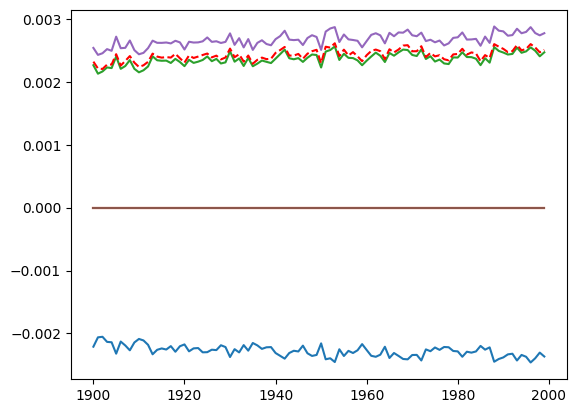

In [355]:
for j in [0,2,5]:
    plt.plot(alt_grad_comps.keys(),alt_grad_comps_numpy[:,j] )
    plt.plot([min(true_grad_comps.keys()),max(true_grad_comps.keys())],[0,0])
plt.plot(alt_grad_comps.keys(),alt_grad_comps_numpy[:,30],"r--" )
plt.show()

    


In [289]:
true_grad_dict[1900]/grad_alt_dict[1900]

array([ 1.47286873e-01,  3.65971745e-01,  8.86065018e-01, -1.18184408e-01,
       -8.37936496e-01, -6.61141286e-02,  3.92097559e+00, -2.40821479e-01,
        2.96811485e-01, -1.56725777e-01,  2.36361726e+00,  3.43529843e-01,
        1.68714365e-01,  1.38507527e-01,  3.77351930e-01, -3.48814485e-01,
        1.77442614e-02, -1.84800302e-01,  1.22764490e-01, -3.98907602e-01,
        7.45984433e-02, -5.27175376e-02,  1.33150843e-01,  8.13393505e-02,
       -1.32787097e+00, -6.79866651e-02,  3.19104910e-01,  7.18939094e-01,
       -1.14393994e+00, -3.04100109e-02, -3.16212068e-02,  1.31558351e-01,
        1.54211577e+00, -2.54805890e-02,  5.34042389e-02, -3.65003337e-01,
       -4.23727056e-01,  1.22197343e-01,  4.35564649e-01, -7.26154815e-03,
        1.14688301e-01,  6.52747516e-02,  1.96091975e-01,  2.30015856e-02,
       -5.16882839e-02,  1.68881573e-01,  3.08151670e-02,  1.17396704e-01,
       -3.86150378e+00,  9.63357072e-03,  7.25945552e-02,  2.37956127e-01,
       -2.06032032e-01,  

In [290]:
true_grad_comps = {}
alt_grad_comps = {}
true_grad_comps_numpy = np.zeros((len(true_grad_dict),31))
alt_grad_comps_numpy = np.zeros((len(grad_alt_dict),31))
for epoch in grad_alt_dict:
    true_grad_comps[epoch] = odt_wts.numpy()@true_grad_dict[epoch]
    true_grad_comps_numpy[epoch-min(true_grad_dict.keys())] = true_grad_comps[epoch]
    alt_grad_comps[epoch] = odt_wts.numpy()@grad_alt_dict[epoch]
    alt_grad_comps_numpy[epoch-min(grad_alt_dict.keys())] = alt_grad_comps[epoch]



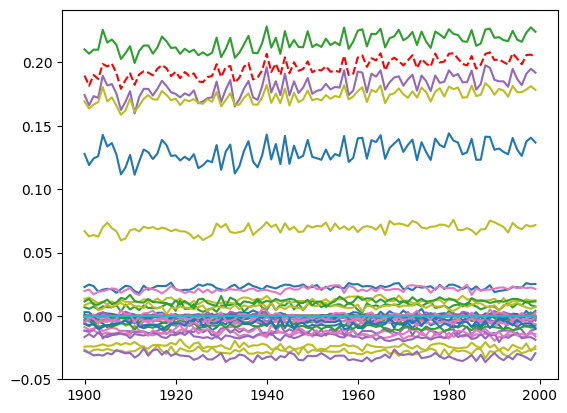

In [299]:

# all paths through node i1 in layer 1
for j in range(30):
    plt.plot(alt_grad_comps.keys(),alt_grad_comps_numpy[:,j] )
    plt.plot([min(true_grad_comps.keys()),max(true_grad_comps.keys())],[0,0])
plt.plot(alt_grad_comps.keys(),alt_grad_comps_numpy[:,30],"r--" )
plt.show()

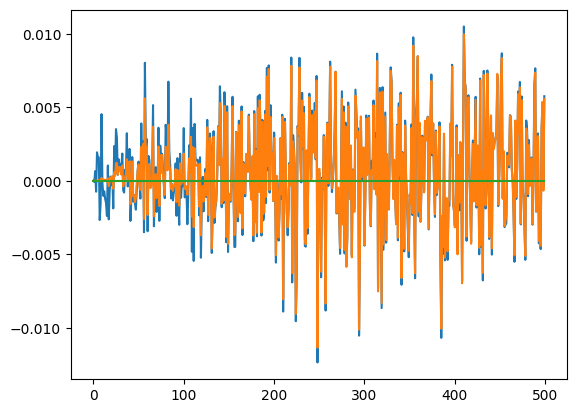

In [108]:
plt.plot(true_grad_comps.keys(),true_grad_comps_numpy[:,0] )
plt.plot(alt_grad_comps.keys(),alt_grad_comps_numpy[:,0] )
plt.plot([min(true_grad_comps.keys()),max(true_grad_comps.keys())],[0,0])

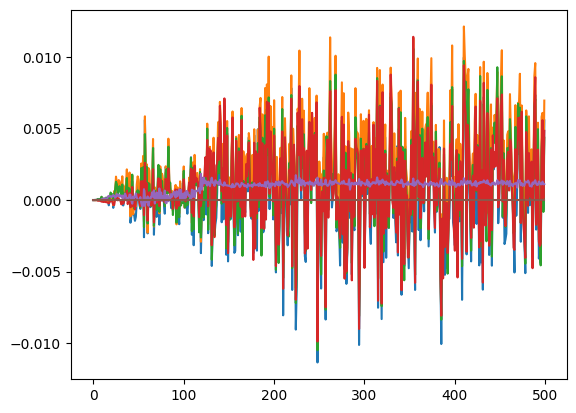

In [97]:
plt.plot(grad_comps.keys(),grad_comps_numpy[:,0])
plt.plot(grad_comps.keys(),grad_comps_numpy[:,2])
plt.plot(grad_comps.keys(),grad_comps_numpy[:,6])
plt.plot(grad_comps.keys(),grad_comps_numpy[:,14])
plt.plot(grad_comps.keys(),grad_comps_numpy[:,30])
plt.plot([min(grad_comps.keys()),max(grad_comps.keys())],[0,0])

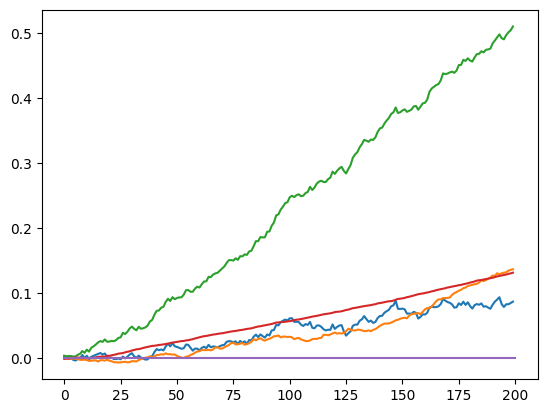

In [65]:
for j in [0,1,2,30]:
    plt.plot(np.cumsum(grad_comps_numpy[100:300,j]))
plt.plot([0,200],[0,0])

In [186]:
W0_comps = {}
W0_comps_numpy = np.zeros((500,31))
for epoch in range(0,500):
    W0_comps[epoch] = odt_wts.numpy()@W0_dict[epoch]
    W0_comps_numpy[epoch] = W0_comps[epoch]


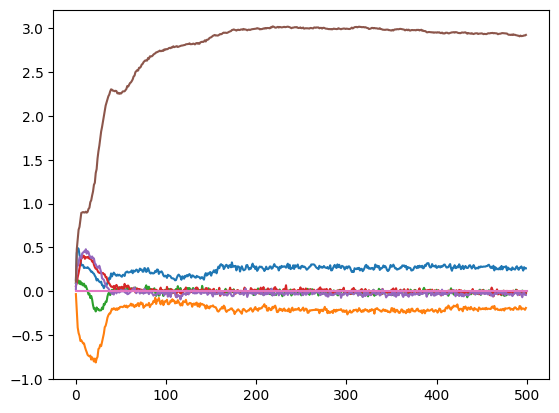

In [188]:

plt.plot(W0_comps.keys(),W0_comps_numpy[:,0])
plt.plot(W0_comps.keys(),W0_comps_numpy[:,2])
plt.plot(W0_comps.keys(),W0_comps_numpy[:,6])
plt.plot(W0_comps.keys(),W0_comps_numpy[:,14])
plt.plot(W0_comps.keys(),W0_comps_numpy[:,30])
plt.plot(W0_comps.keys(),W0_comps_numpy[:,24])
plt.plot([0,500],[0,0])

In [108]:
print(np.max(np.abs(odt_wts.numpy()@grad_alt)))
print(np.argmax(np.abs(odt_wts.numpy()@grad_alt)))
print(odt_wts.numpy()@grad_alt)
print(odt_wts.numpy()@true_grad)

0.004479202994418259
2
[ 3.81081935e-03  2.70010123e-04  4.47920299e-03  2.95804022e-04
  8.86006654e-04 -5.33267421e-04  3.20481095e-03  2.88055942e-04
  5.99186725e-04  3.25973334e-04 -5.64864273e-05  3.22930861e-04
  6.29857492e-04 -8.34030014e-04  2.58873003e-03  7.00441191e-05
  2.92297458e-04  9.32298677e-04 -1.49379927e-05  6.06151467e-05
 -4.09736645e-04 -1.51455845e-04 -3.24845902e-04 -2.13612873e-04
 -3.01012043e-05  1.22585382e-03  2.46137723e-04  2.19183108e-04
 -1.12042957e-03  1.10557638e-03 -9.68425624e-04]
[ 3.8108178e-03  2.7000523e-04  4.4792024e-03  2.9580234e-04
  8.8600430e-04 -5.3326529e-04  3.2048114e-03  2.8805828e-04
  5.9918658e-04  3.2597760e-04 -5.6485311e-05  3.2293270e-04
  6.2985253e-04 -8.3402666e-04  2.5887275e-03  7.0044553e-05
  2.9229585e-04  9.3228830e-04 -1.4938079e-05  6.0613820e-05
 -4.0973868e-04 -1.5145550e-04 -3.2484136e-04 -2.1361304e-04
 -3.0102354e-05  1.2258515e-03  2.4613913e-04  2.1918071e-04
 -1.1204297e-03  1.1055702e-03 -9.6842099e-04

In [92]:
W0[i1]@odt_wts[30]/(torch.norm(W0[i1])*torch.norm(odt_wts[30]))

tensor(-0.8669)

In [108]:
u_ODT_node = seed_result["tree"].w_list[ODT_INTERNAL_NODE_ID]
print("Cosine similarity between grad_alt for neuron i1 and u_ODT_node at epoch", EPOCH, ":", grad_alt@u_ODT_node/(np.linalg.norm(u_ODT_node)*np.linalg.norm(grad_alt)))
print("Norm of grad_alt:", np.linalg.norm(grad_alt))

Cosine similarity between grad_alt for neuron i1 and u_ODT_node at epoch 2 : 0.24897442004383827
Norm of grad_alt: 0.002980160197043697


In [ ]:
from layer_lenses.relu_analysis import summarize_neuron_leaf_activity

checkpoint_model = checkpoint_model_from_state(seed_result["out"]["model"], ckpts[EPOCH])

neuron_leaf_activity_summary = summarize_neuron_leaf_activity(
    model=checkpoint_model,
    x_eval=seed_result["data"]["x_eval"],
    tree=seed_result["tree"],
)

# display(neuron_leaf_activity_summary)
# show(
#     neuron_leaf_activity_summary,
#     scrollY="500px",
#     scrollX=True,
#     search=True,
#     paging=True,
#     pageLength=25,
# )

In [ ]:
# Build: neuron -> activity vector over ODT leaves
# Input: neuron_leaf_activity_summary (DataFrame from earlier cell)
# Output: neuron_to_leaf_activity (dict)

from layer_lenses.relu_analysis import neuron_leaf_activity_dict

neuron_to_leaf_activity, neuron_activity_leaf_order = neuron_leaf_activity_dict(
    neuron_leaf_activity_summary,
    key_mode="layer_local",
)

print(f"Built dictionary for {len(neuron_to_leaf_activity)} neurons.")
print(f"Vector length per neuron: {len(neuron_activity_leaf_order)} leaves")
print("Example key:", next(iter(neuron_to_leaf_activity)))
print("Example vector:", neuron_to_leaf_activity[next(iter(neuron_to_leaf_activity))])

In [ ]:
neuron_to_leaf_activity[(1,7)]

## Start/end metrics

This block computes start/end metrics for the selected seed.

In [43]:
if seed_result is None:
    raise ValueError("Run the training cell first to populate seed_result.")

rows = collect_start_end_metrics(seed_result)
metrics_table = pd.DataFrame(rows).sort_values(["timepoint"]).reset_index(drop=True)
display(metrics_table)

,timepoint,epoch,train_log_loss,test_error
0,end,999,3.866920e-08,0.313962
1,start,0,6.932027e-01,0.503537


## Quick visualization

Bar plots for start vs end test error and train log loss for the selected seed.

In [ ]:
if seed_result is None:
    raise ValueError("Run the training cell first to populate seed_result.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(metrics_table["timepoint"], metrics_table["test_error"])
axes[0].set_title("Test error")

axes[1].bar(metrics_table["timepoint"], metrics_table["train_log_loss"])
axes[1].set_title("Train log loss")

plt.tight_layout()
plt.show()